# Step 1: Install the required libraries

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn joblib

# Step 2: Import the libraries

In [2]:
# Data manipulation
import os
import warnings
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import calibration_curve

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    precision_recall_fscore_support
)

# Feature importance
from sklearn.inspection import permutation_importance

# Saving models and results
import joblib

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

# Step 3: Load the dataset

In [3]:
DATA_PATH = "hotel_bookings_updated_2024.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (119390, 33)


# Step 4: Initial dataset inspection

In [4]:
print("First five records:")
display(df.head())

First five records:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,city
0,Resort Hotel - Chandigarh,0,342,2024,July,30,27,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2024-07-27 22:16:40.916332324,Chandigarh
1,Resort Hotel - Mumbai,0,737,2024,April,17,28,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2024-04-28 21:56:21.507509066,Mumbai
2,Resort Hotel - Delhi,0,7,2024,September,37,10,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2024-09-10 03:46:25.734029096,Delhi
3,Resort Hotel - Kolkata,0,13,2024,August,33,14,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2024-08-14 18:07:10.049669568,Kolkata
4,Resort Hotel - Lucknow,0,14,2024,September,37,14,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2024-09-14 14:27:32.473846000,Lucknow


In [5]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  


In [6]:
print("Descriptive statistics:")
display(df.describe(include="all").T)

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,30,City Hotel - Ahmedabad,5405,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2024.0,0.0,2024.0,2024.0,2024.0,2024.0,2024.0
arrival_date_month,119390,12,October,10349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,26.375835,15.021596,1.0,13.0,26.0,39.0,52.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.723394,8.805079,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


In [7]:
print("Column names:")
print(df.columns.tolist())

Column names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date', 'city']


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
print("Missing values:")
missing_values = df.isna().sum().sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (missing_values / len(df)) * 100
})

display(missing_summary[missing_summary["Missing_Count"] > 0])

Missing values:


,Missing_Count,Missing_Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


# Step 5: Inspect the target variable

In [10]:
target_counts = df["is_canceled"].value_counts().sort_index()

print(target_counts)

is_canceled
0    75166
1    44224
Name: count, dtype: int64


In [11]:
target_percentages = (
    df["is_canceled"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print(target_percentages)

is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


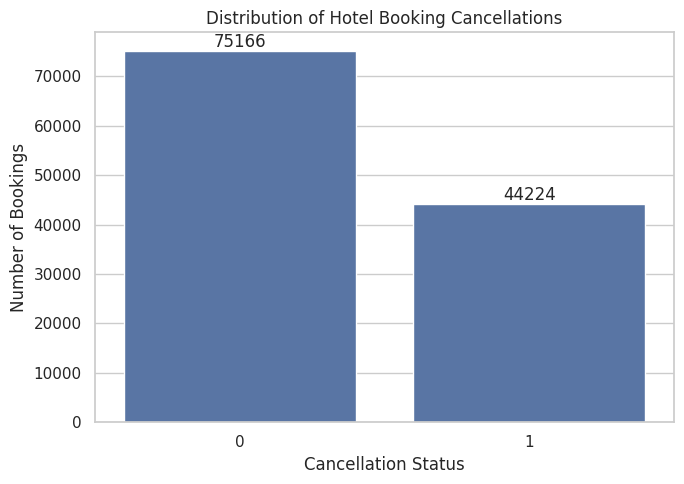

In [12]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="is_canceled"
)

plt.title("Distribution of Hotel Booking Cancellations")
plt.xlabel("Cancellation Status")
plt.ylabel("Number of Bookings")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

# Step 6: Remove duplicate records

In [13]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows before removal:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after duplicate removal:", df.shape)

Duplicate rows before removal: 0
Dataset shape after duplicate removal: (119390, 33)


# Step 7: Identify data leakage

In [14]:
possible_leakage_columns = [
    "reservation_status",
    "reservation_status_date"
]

existing_leakage_columns = [
    column
    for column in possible_leakage_columns
    if column in df.columns
]

print("Leakage columns found:")
print(existing_leakage_columns)

Leakage columns found:
['reservation_status', 'reservation_status_date']


In [15]:
df = df.drop(
    columns=existing_leakage_columns
)

print("Dataset shape after leakage removal:")
print(df.shape)

Dataset shape after leakage removal:
(119390, 31)


In [16]:
additional_post_booking_columns = [
    "assigned_room_type",
    "booking_changes"
]

existing_additional_columns = [
    column
    for column in additional_post_booking_columns
    if column in df.columns
]

print("Additional post-booking columns found:")
print(existing_additional_columns)

Additional post-booking columns found:
['assigned_room_type', 'booking_changes']


In [17]:
df = df.drop(
    columns=existing_additional_columns
)

print("Final dataset shape after leakage control:")
print(df.shape)

Final dataset shape after leakage control:
(119390, 29)


# Step 8: Basic data cleaning

In [18]:
numeric_columns_to_check = [
    "lead_time",
    "adults",
    "children",
    "babies",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

for column in numeric_columns_to_check:
    if column in df.columns:
        print(f"\n{column}")
        print(df[column].describe())


lead_time
count    119390.000000
mean        104.011416
std         106.863097
min           0.000000
25%          18.000000
50%          69.000000
75%         160.000000
max         737.000000
Name: lead_time, dtype: float64

adults
count    119390.000000
mean          1.856403
std           0.579261
min           0.000000
25%           2.000000
50%           2.000000
75%           2.000000
max          55.000000
Name: adults, dtype: float64

children
count    119386.000000
mean          0.103890
std           0.398561
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          10.000000
Name: children, dtype: float64

babies
count    119390.000000
mean          0.007949
std           0.097436
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          10.000000
Name: babies, dtype: float64

stays_in_weekend_nights
count    119390.000000
mean          0.927599
std           0.998613
min         

In [19]:
if all(
    column in df.columns
    for column in ["adults", "children", "babies"]
):
    invalid_guest_rows = df[
        (df["adults"] == 0) &
        (df["children"] == 0) &
        (df["babies"] == 0)
    ]

    print("Bookings with no recorded guests:", len(invalid_guest_rows))
    display(invalid_guest_rows.head())

Bookings with no recorded guests: 180


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,city
2224,Resort Hotel - Delhi,0,1,2024,March,10,10,0,3,0,0.0,0,SC,PRT,Corporate,Corporate,0,0,0,A,No Deposit,NaN,174.0,0,Transient-Party,0.0,0,0,Delhi
2409,Resort Hotel - Lucknow,0,0,2024,January,4,25,0,0,0,0.0,0,SC,PRT,Corporate,Corporate,0,0,0,A,No Deposit,NaN,174.0,0,Transient,0.0,0,0,Lucknow
3181,Resort Hotel - Ahmedabad,0,36,2024,February,7,18,1,2,0,0.0,0,SC,ESP,Groups,TA/TO,0,0,0,A,No Deposit,38.0,NaN,0,Transient-Party,0.0,0,0,Ahmedabad
3684,Resort Hotel - Pune,0,165,2024,October,41,9,1,4,0,0.0,0,SC,PRT,Groups,TA/TO,0,0,0,A,No Deposit,308.0,NaN,122,Transient-Party,0.0,0,0,Pune
3708,Resort Hotel - Jaipur,0,165,2024,October,40,5,2,4,0,0.0,0,SC,PRT,Groups,TA/TO,0,0,0,A,No Deposit,308.0,NaN,122,Transient-Party,0.0,0,0,Jaipur


In [20]:
if all(
    column in df.columns
    for column in ["adults", "children", "babies"]
):
    df = df[
        ~(
            (df["adults"] == 0) &
            (df["children"] == 0) &
            (df["babies"] == 0)
        )
    ].copy()

In [21]:
missing_after_cleaning = df.isna().sum().sort_values(ascending=False)

display(
    pd.DataFrame({
        "Missing_Count": missing_after_cleaning,
        "Missing_Percentage": (
            missing_after_cleaning / len(df) * 100
        ).round(2)
    }).query("Missing_Count > 0")
)

,Missing_Count,Missing_Percentage
company,112442,94.32
agent,16280,13.66
country,478,0.40
children,4,0.00


In [22]:
if "company" in df.columns:
    company_missing_percentage = df["company"].isna().mean() * 100

    print(
        f"Company missing percentage: "
        f"{company_missing_percentage:.2f}%"
    )

    df = df.drop(columns=["company"])

Company missing percentage: 94.32%


# Step 9: Feature engineering

9.1 Create total guests

In [23]:
guest_columns = [
    "adults",
    "children",
    "babies"
]

if all(column in df.columns for column in guest_columns):
    df["total_guests"] = (
        df["adults"] +
        df["children"].fillna(0) +
        df["babies"]
    )

9.2 Create total nights

In [24]:
night_columns = [
    "stays_in_weekend_nights",
    "stays_in_week_nights"
]

if all(column in df.columns for column in night_columns):
    df["total_nights"] = (
        df["stays_in_weekend_nights"] +
        df["stays_in_week_nights"]
    )

9.3 Create total stay value

In [25]:
if "adr" in df.columns and "total_nights" in df.columns:
    df["estimated_booking_value"] = (
        df["adr"] * df["total_nights"]
    )

9.4 Create a weekend-stay indicator

In [26]:
if "stays_in_weekend_nights" in df.columns:
    df["has_weekend_stay"] = (
        df["stays_in_weekend_nights"] > 0
    ).astype(int)

9.5 Create a special-request indicator

In [27]:
if "total_of_special_requests" in df.columns:
    df["has_special_request"] = (
        df["total_of_special_requests"] > 0
    ).astype(int)

9.6 Create a long-lead-time indicator

In [28]:
if "lead_time" in df.columns:
    df["long_lead_time"] = (
        df["lead_time"] > df["lead_time"].median()
    ).astype(int)

In [29]:
display(df.head())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,city,total_guests,total_nights,estimated_booking_value,has_weekend_stay,has_special_request,long_lead_time
0,Resort Hotel - Chandigarh,0,342,2024,July,30,27,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,No Deposit,NaN,0,Transient,0.0,0,0,Chandigarh,2.0,0,0.0,0,0,1
1,Resort Hotel - Mumbai,0,737,2024,April,17,28,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,No Deposit,NaN,0,Transient,0.0,0,0,Mumbai,2.0,0,0.0,0,0,1
2,Resort Hotel - Delhi,0,7,2024,September,37,10,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,No Deposit,NaN,0,Transient,75.0,0,0,Delhi,1.0,1,75.0,0,0,0
3,Resort Hotel - Kolkata,0,13,2024,August,33,14,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,No Deposit,304.0,0,Transient,75.0,0,0,Kolkata,1.0,1,75.0,0,0,0
4,Resort Hotel - Lucknow,0,14,2024,September,37,14,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,No Deposit,240.0,0,Transient,98.0,0,1,Lucknow,2.0,2,196.0,0,1,0


# Step 10: Exploratory Data Analysis

10.1 Cancellation rate by hotel type

,hotel,Cancellation_Rate
0,City Hotel - Ahmedabad,42.311260
1,City Hotel - Bangalore,43.316022
2,City Hotel - Bhopal,40.686823
3,City Hotel - Chandigarh,41.690354
4,City Hotel - Chennai,41.395083
5,City Hotel - Delhi,41.374046
6,City Hotel - Goa,41.562618
7,City Hotel - Hyderabad,42.331519
8,City Hotel - Indore,41.868579
9,City Hotel - Jaipur,41.291291


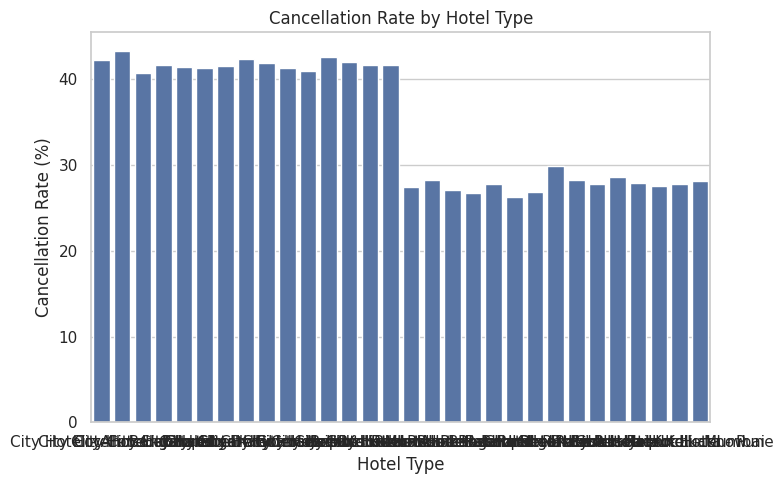

In [30]:
if "hotel" in df.columns:
    hotel_cancellation = (
        df.groupby("hotel")["is_canceled"]
        .mean()
        .mul(100)
        .reset_index(name="Cancellation_Rate")
    )

    display(hotel_cancellation)

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=hotel_cancellation,
        x="hotel",
        y="Cancellation_Rate"
    )

    plt.title("Cancellation Rate by Hotel Type")
    plt.xlabel("Hotel Type")
    plt.ylabel("Cancellation Rate (%)")
    plt.tight_layout()
    plt.show()

10.2 Cancellation rate by deposit type

,deposit_type,Cancellation_Rate
1,Non Refund,99.362446
0,No Deposit,28.401987
2,Refundable,22.222222


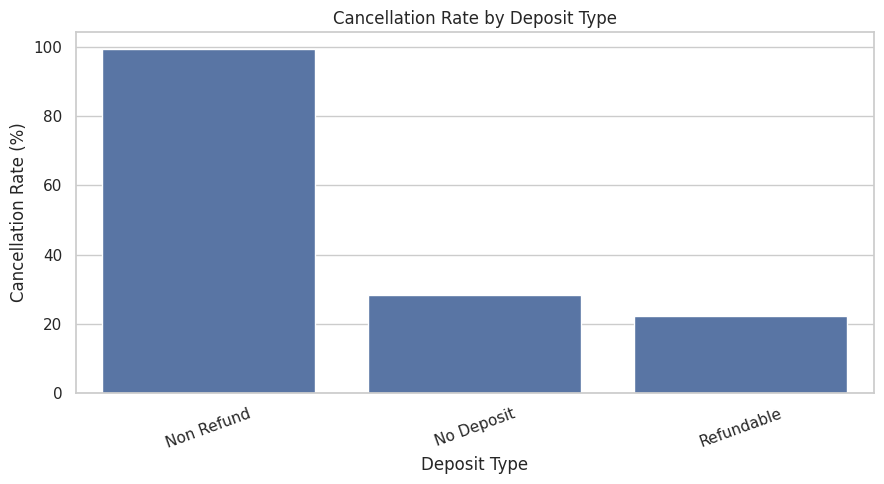

In [31]:
if "deposit_type" in df.columns:
    deposit_cancellation = (
        df.groupby("deposit_type")["is_canceled"]
        .mean()
        .mul(100)
        .reset_index(name="Cancellation_Rate")
        .sort_values("Cancellation_Rate", ascending=False)
    )

    display(deposit_cancellation)

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=deposit_cancellation,
        x="deposit_type",
        y="Cancellation_Rate"
    )

    plt.title("Cancellation Rate by Deposit Type")
    plt.xlabel("Deposit Type")
    plt.ylabel("Cancellation Rate (%)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

10.3 Cancellation rate by market segment

,market_segment,Cancellation_Rate
7,Undefined,100.000000
4,Groups,61.108585
6,Online TA,36.758970
5,Offline TA/TO,34.331321
0,Aviation,22.127660
2,Corporate,18.761833
3,Direct,15.371165
1,Complementary,12.225275


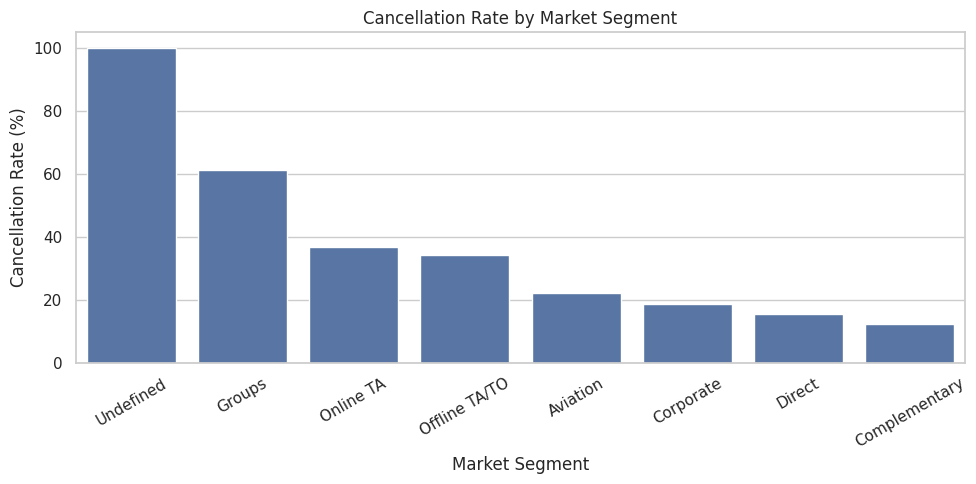

In [32]:
if "market_segment" in df.columns:
    segment_cancellation = (
        df.groupby("market_segment")["is_canceled"]
        .mean()
        .mul(100)
        .reset_index(name="Cancellation_Rate")
        .sort_values("Cancellation_Rate", ascending=False)
    )

    display(segment_cancellation)

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=segment_cancellation,
        x="market_segment",
        y="Cancellation_Rate"
    )

    plt.title("Cancellation Rate by Market Segment")
    plt.xlabel("Market Segment")
    plt.ylabel("Cancellation Rate (%)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

10.4 Lead time distribution

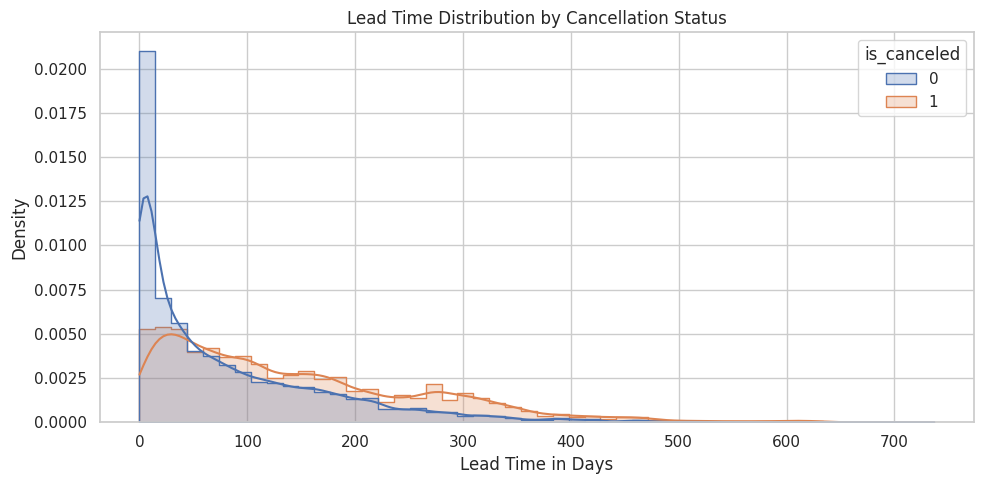

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="lead_time",
    hue="is_canceled",
    bins=50,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Lead Time Distribution by Cancellation Status")
plt.xlabel("Lead Time in Days")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

10.5 Lead time comparison

In [34]:
lead_time_summary = (
    df.groupby("is_canceled")["lead_time"]
    .agg(["mean", "median", "std", "min", "max"])
)

display(lead_time_summary)

,mean,median,std,min,max
is_canceled,,,,,
0,80.082028,45.0,91.137797,0,737
1,144.886264,113.0,118.611795,0,629


10.6 Cancellation rate by customer type

,customer_type,Cancellation_Rate
2,Transient,40.786356
0,Contract,30.992141
3,Transient-Party,25.450415
1,Group,10.104530


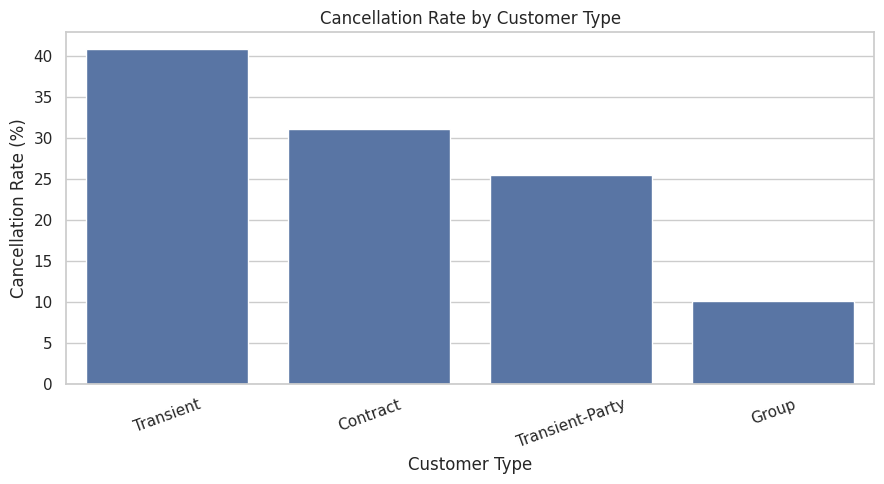

In [35]:
if "customer_type" in df.columns:
    customer_cancellation = (
        df.groupby("customer_type")["is_canceled"]
        .mean()
        .mul(100)
        .reset_index(name="Cancellation_Rate")
        .sort_values("Cancellation_Rate", ascending=False)
    )

    display(customer_cancellation)

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=customer_cancellation,
        x="customer_type",
        y="Cancellation_Rate"
    )

    plt.title("Cancellation Rate by Customer Type")
    plt.xlabel("Customer Type")
    plt.ylabel("Cancellation Rate (%)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

10.7 Correlation analysis

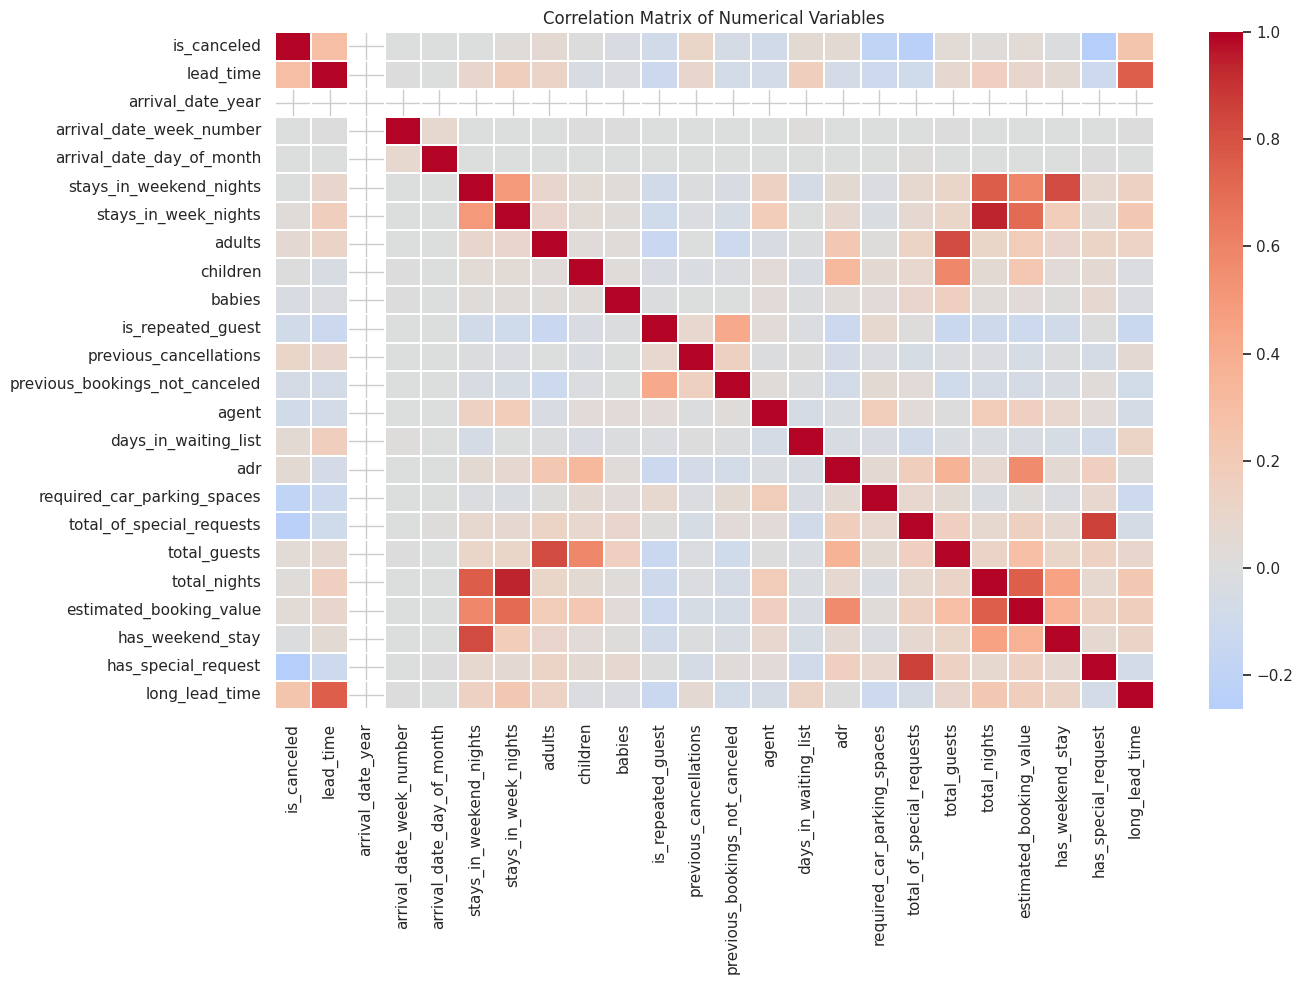

In [36]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

# Step 11: Define the modelling dataset

In [37]:
X = df.drop(columns=["is_canceled"])
y = df["is_canceled"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (119210, 33)
Target shape: (119210,)


In [38]:
print(y.value_counts())
print(y.value_counts(normalize=True).mul(100).round(2))

is_canceled
0    75011
1    44199
Name: count, dtype: int64
is_canceled
0    62.92
1    37.08
Name: proportion, dtype: float64


# Step 12: Train-test split

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))
print("Testing target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training feature shape: (95368, 33)
Testing feature shape: (23842, 33)
Training target distribution:
is_canceled
0    62.92
1    37.08
Name: proportion, dtype: float64
Testing target distribution:
is_canceled
0    62.92
1    37.08
Name: proportion, dtype: float64


# Step 13: Identify numerical and categorical columns

In [40]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'agent', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_guests', 'total_nights', 'estimated_booking_value', 'has_weekend_stay', 'has_special_request', 'long_lead_time']

Categorical features:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'city']


# Step 14: Build the preprocessing pipeline

In [41]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

# Step 15: Create the Logistic Regression model

In [42]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ]
)

In [43]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


# Step 16: Create the Random Forest model

In [44]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=250,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

In [45]:
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


# Step 17: Evaluate the models

In [46]:
def evaluate_model(model, model_name, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1_Score": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_test,
            probabilities
        )
    }

    print(f"\n{model_name}")
    print("-" * len(model_name))
    print(classification_report(
        y_test,
        predictions,
        target_names=[
            "Not Cancelled",
            "Cancelled"
        ],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    return results

In [47]:
logistic_results = evaluate_model(
    logistic_model,
    "Logistic Regression",
    X_test,
    y_test
)


Logistic Regression
-------------------
               precision    recall  f1-score   support

Not Cancelled       0.86      0.83      0.84     15002
    Cancelled       0.72      0.76      0.74      8840

     accuracy                           0.80     23842
    macro avg       0.79      0.80      0.79     23842
 weighted avg       0.81      0.80      0.81     23842

Confusion Matrix:
[[12436  2566]
 [ 2102  6738]]


In [48]:
random_forest_results = evaluate_model(
    random_forest_model,
    "Random Forest",
    X_test,
    y_test
)


Random Forest
-------------
               precision    recall  f1-score   support

Not Cancelled       0.86      0.93      0.90     15002
    Cancelled       0.87      0.75      0.80      8840

     accuracy                           0.86     23842
    macro avg       0.87      0.84      0.85     23842
 weighted avg       0.86      0.86      0.86     23842

Confusion Matrix:
[[14005   997]
 [ 2230  6610]]


# Step 18: Compare model performance

In [49]:
results_df = pd.DataFrame([
    logistic_results,
    random_forest_results
])

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_Score": "{:.4f}",
        "ROC_AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.8042,0.7242,0.7622,0.7427,0.8890
1,Random Forest,0.8647,0.8689,0.7477,0.8038,0.9412


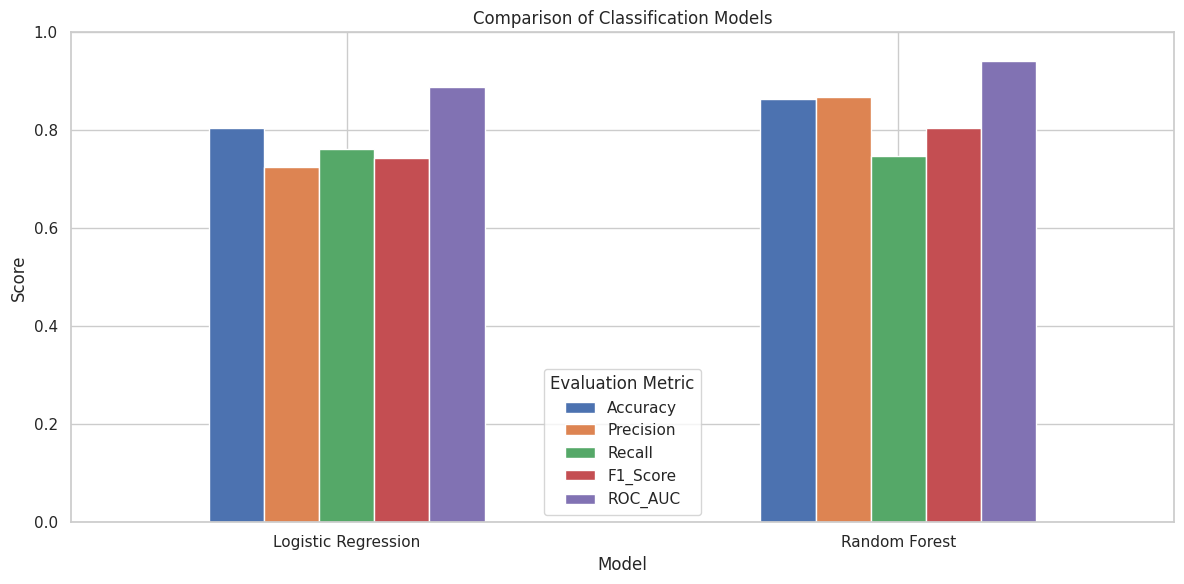

In [50]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC"
]

plot_df = results_df.set_index("Model")[metrics_to_plot]

plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Classification Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

# Step 19: Plot confusion matrices

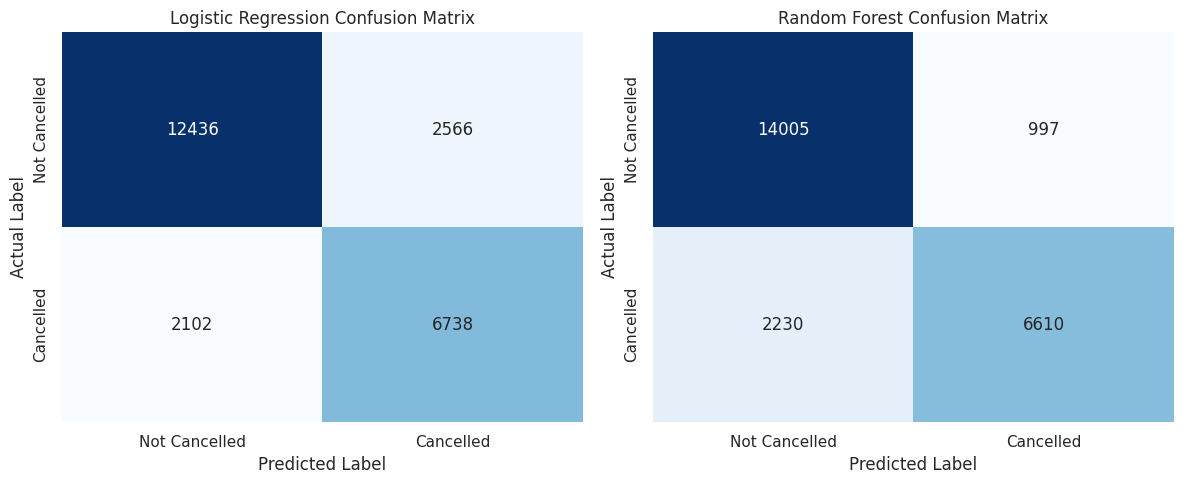

In [51]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

models = [
    ("Logistic Regression", logistic_model),
    ("Random Forest", random_forest_model)
]

for ax, (name, model) in zip(axes, models):
    predictions = model.predict(X_test)

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
    ax.set_xticklabels(["Not Cancelled", "Cancelled"])
    ax.set_yticklabels(["Not Cancelled", "Cancelled"])

plt.tight_layout()
plt.show()

# Step 20: Plot ROC curves

<Figure size 900x600 with 0 Axes>

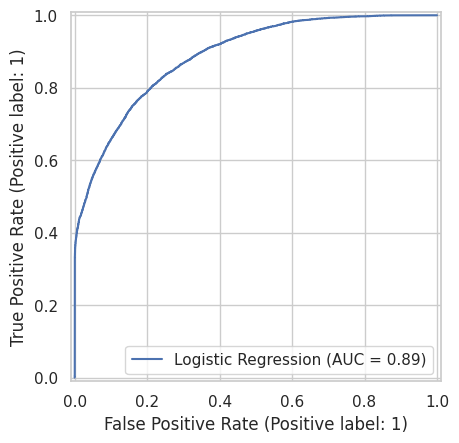

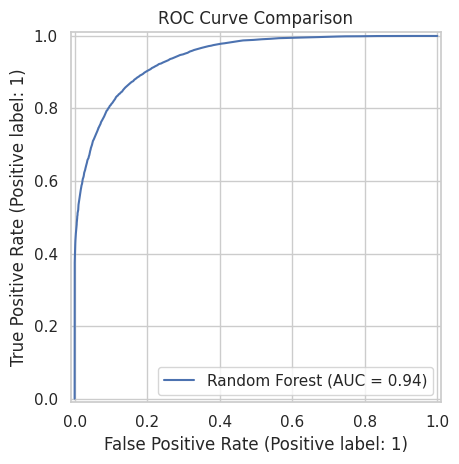

In [52]:
plt.figure(figsize=(9, 6))

RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    name="Logistic Regression"
)

RocCurveDisplay.from_estimator(
    random_forest_model,
    X_test,
    y_test,
    name="Random Forest"
)

plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

# Step 21: Select the best model

In [53]:
best_model_name = results_df.loc[
    results_df["ROC_AUC"].idxmax(),
    "Model"
]

print("Best model based on ROC-AUC:", best_model_name)

Best model based on ROC-AUC: Random Forest


In [54]:
if best_model_name == "Logistic Regression":
    best_model = logistic_model
else:
    best_model = random_forest_model

# Step 22: Analyse feature importance

In [79]:
# Extract the fitted preprocessing component from the trained
# Random Forest pipeline.

fitted_preprocessor = random_forest_model.named_steps[
    "preprocessor"
]

fitted_random_forest = random_forest_model.named_steps[
    "classifier"
]

# Transform the data using the already-fitted preprocessing pipeline.

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

# Retrieve the transformed feature names.

feature_names = fitted_preprocessor.get_feature_names_out()

print(
    "Number of transformed features:",
    len(feature_names)
)

Number of transformed features: 283


In [80]:
feature_names = preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))

Number of transformed features: 283


In [57]:
rf_for_importance = RandomForestClassifier(
    n_estimators=250,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_for_importance.fit(X_train_transformed, y_train)

RandomForestClassifier(class_weight='balanced_subsample', n_estimators=250,
                       n_jobs=-1, random_state=42)

In [81]:
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_random_forest.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df.head(20))

,Feature,Importance
0,numeric__lead_time,0.077592
199,categorical__country_PRT,0.060324
262,categorical__deposit_type_Non Refund,0.051705
14,numeric__adr,0.050247
19,numeric__estimated_booking_value,0.048186
261,categorical__deposit_type_No Deposit,0.045340
12,numeric__agent,0.042897
3,numeric__arrival_date_day_of_month,0.032908
2,numeric__arrival_date_week_number,0.031308
16,numeric__total_of_special_requests,0.030663


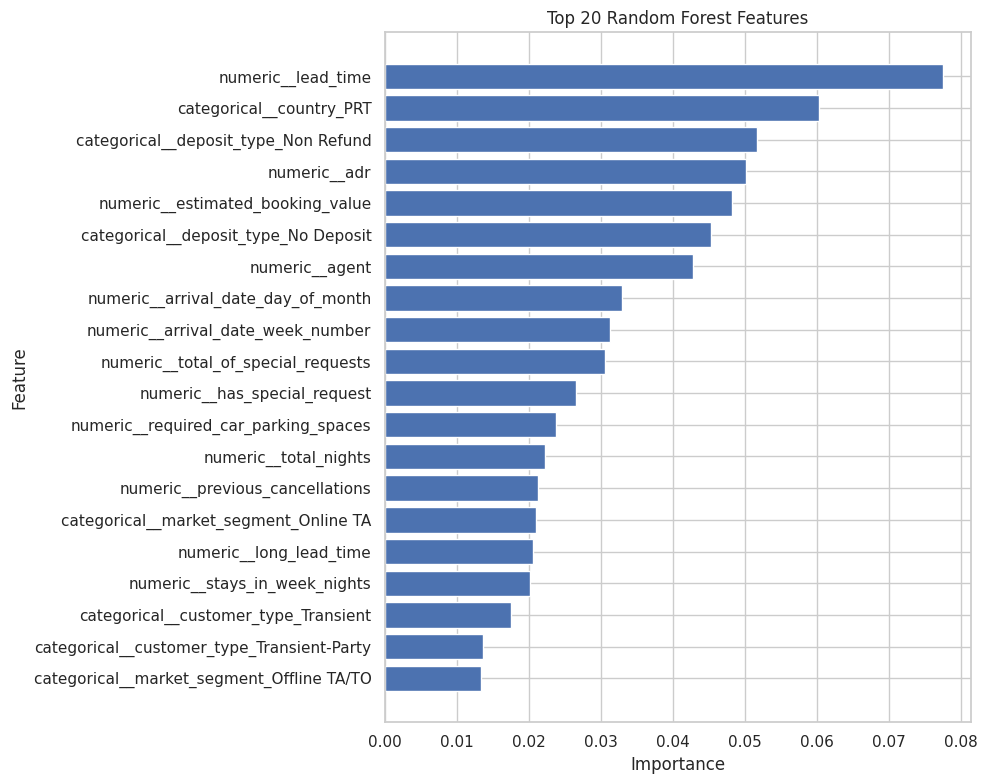

In [59]:
top_features = feature_importance_df.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 20 Random Forest Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Step 23: Use permutation importance

In [61]:
permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="roc_auc",
    n_jobs=1
)

In [62]:
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
}).sort_values(
    by="Importance_Mean",
    ascending=False
)

display(permutation_df.head(20))

,Feature,Importance_Mean,Importance_Std
12,country,0.082276,0.000362
19,deposit_type,0.046470,0.000652
13,market_segment,0.043081,0.000987
22,customer_type,0.035324,0.001687
1,lead_time,0.024418,0.000757
24,required_car_parking_spaces,0.016733,0.000701
20,agent,0.016325,0.000457
16,previous_cancellations,0.011836,0.000307
31,has_special_request,0.009236,0.000859
25,total_of_special_requests,0.008844,0.000780


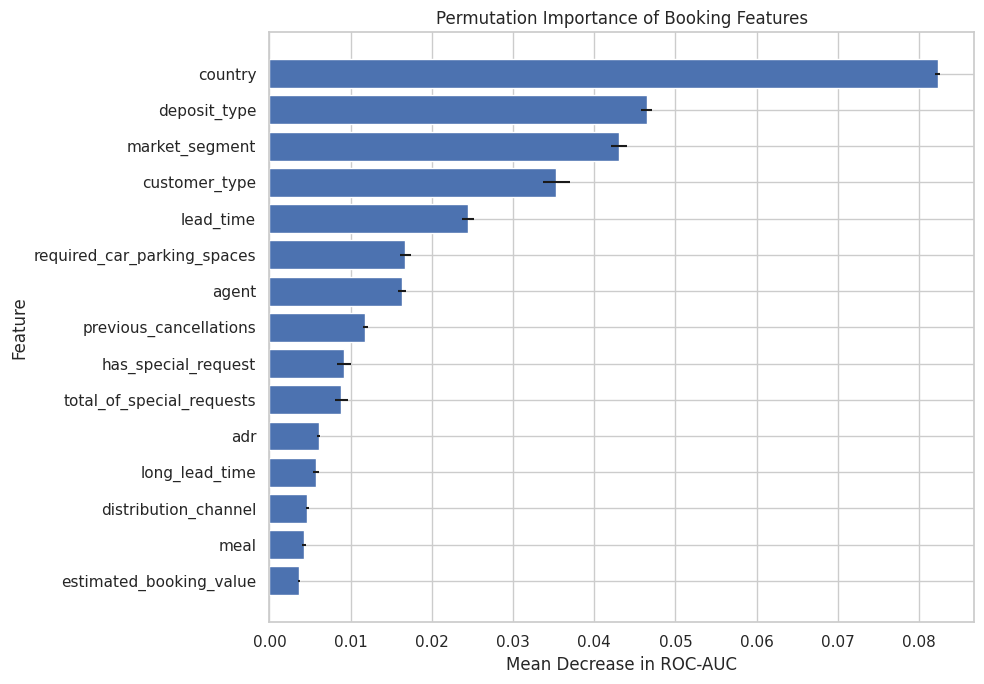

In [63]:
top_permutation_features = permutation_df.head(15).sort_values(
    by="Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_permutation_features["Feature"],
    top_permutation_features["Importance_Mean"],
    xerr=top_permutation_features["Importance_Std"]
)

plt.title("Permutation Importance of Booking Features")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Step 24: Generate business-level cancellation risk groups

In [64]:
# Generate predictions for the test dataset

risk_output = X_test.copy()

# Actual cancellation outcome
risk_output["actual_cancellation"] = y_test.to_numpy()

# Predicted cancellation class
risk_output["predicted_cancellation"] = (
    best_model.predict(X_test)
)

# Probability of cancellation
risk_output["cancellation_probability"] = (
    best_model.predict_proba(X_test)[:, 1]
)

display(risk_output.head())

,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,city,total_guests,total_nights,estimated_booking_value,has_weekend_stay,has_special_request,long_lead_time,actual_cancellation,predicted_cancellation,cancellation_probability
93855,City Hotel - Bangalore,3,2024,June,25,20,1,2,2,2.0,0,BB,ESP,Direct,Direct,0,0,0,E,No Deposit,14.0,0,Transient,205.33,0,2,Bangalore,4.0,3,615.99,1,1,0,0,0,0.048
106322,City Hotel - Chandigarh,0,2024,February,7,13,1,3,2,0.0,0,BB,FRA,Direct,Direct,0,0,0,D,No Deposit,NaN,0,Transient,100.30,0,0,Chandigarh,2.0,4,401.20,1,0,0,0,0,0.060
47087,City Hotel - Mumbai,49,2024,December,52,24,2,2,2,0.0,0,BB,NLD,Online TA,TA/TO,0,0,0,D,No Deposit,9.0,0,Transient,84.45,0,2,Mumbai,2.0,4,337.80,1,1,0,0,0,0.168
82274,City Hotel - Lucknow,47,2024,August,33,16,0,1,1,0.0,0,BB,MUS,Online TA,TA/TO,0,0,0,A,No Deposit,9.0,0,Transient,81.00,0,2,Lucknow,1.0,1,81.00,0,1,0,0,0,0.176
96574,City Hotel - Ahmedabad,142,2024,January,1,6,2,5,2,0.0,0,BB,NOR,Direct,Direct,0,0,0,A,No Deposit,14.0,0,Transient,133.00,0,0,Ahmedabad,2.0,7,931.00,1,0,1,0,0,0.352


# Step 25: Create cancellation risk categories

In [65]:
risk_output["risk_group"] = pd.cut(
    risk_output["cancellation_probability"],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)

display(
    risk_output[
        [
            "actual_cancellation",
            "predicted_cancellation",
            "cancellation_probability",
            "risk_group"
        ]
    ].head(20)
)

,actual_cancellation,predicted_cancellation,cancellation_probability,risk_group
93855,0,0,0.048,Low Risk
106322,0,0,0.060,Low Risk
47087,0,0,0.168,Low Risk
82274,0,0,0.176,Low Risk
96574,0,0,0.352,Medium Risk
82608,0,0,0.176,Low Risk
3099,1,1,0.820,High Risk
82926,1,1,1.000,High Risk
103196,0,0,0.096,Low Risk
64625,1,0,0.472,Medium Risk


# Step 26: Analyse the distribution of risk groups

In [78]:
risk_distribution = (
    risk_output["risk_group"]
    .value_counts()
    .reindex(
        ["Low Risk", "Medium Risk", "High Risk"],
        fill_value=0
    )
    .reset_index()
)

risk_distribution.columns = [
    "Risk_Group",
    "Number_of_Bookings"
]

display(risk_distribution)

,Risk_Group,Number_of_Bookings
0,Low Risk,13090
1,Medium Risk,4311
2,High Risk,6441


# Step 27: Visualise the risk groups

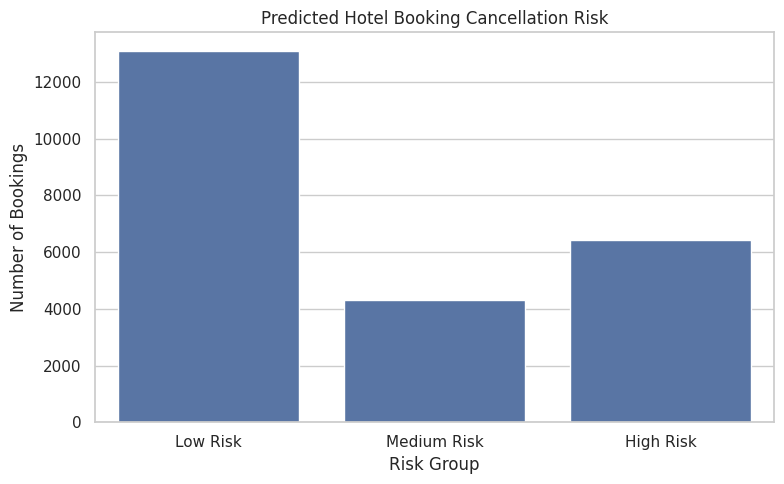

In [66]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=risk_output,
    x="risk_group",
    order=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)

plt.title("Predicted Hotel Booking Cancellation Risk")
plt.xlabel("Risk Group")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()

# Step 28: Check actual cancellation rates within risk groups

In [67]:
risk_performance = (
    risk_output
    .groupby("risk_group", observed=False)
    .agg(
        bookings=("actual_cancellation", "count"),
        actual_cancellations=("actual_cancellation", "sum"),
        average_predicted_probability=(
            "cancellation_probability",
            "mean"
        )
    )
    .reset_index()
)

risk_performance["actual_cancellation_rate"] = (
    risk_performance["actual_cancellations"] /
    risk_performance["bookings"] *
    100
)

risk_performance["average_predicted_probability"] = (
    risk_performance["average_predicted_probability"] * 100
)

risk_performance["actual_cancellation_rate"] = (
    risk_performance["actual_cancellation_rate"].round(2)
)

risk_performance["average_predicted_probability"] = (
    risk_performance["average_predicted_probability"].round(2)
)

display(risk_performance)

,risk_group,bookings,actual_cancellations,average_predicted_probability,actual_cancellation_rate
0,Low Risk,13090,922,10.85,7.04
1,Medium Risk,4311,2052,43.34,47.60
2,High Risk,6441,5866,86.65,91.07


# Step 29: Inspect high-risk bookings

In [68]:
high_risk_bookings = risk_output[
    risk_output["risk_group"] == "High Risk"
].copy()

print("Number of high-risk bookings:", len(high_risk_bookings))

display(high_risk_bookings.head(20))

Number of high-risk bookings: 6441


,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,city,total_guests,total_nights,estimated_booking_value,has_weekend_stay,has_special_request,long_lead_time,actual_cancellation,predicted_cancellation,cancellation_probability,risk_group
3099,Resort Hotel - Bangalore,97,2024,September,38,22,6,15,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,No Deposit,240.0,0,Transient,32.40,0,1,Bangalore,2.0,21,680.40,1,1,1,1,1,0.820,High Risk
82926,City Hotel - Mumbai,177,2024,January,3,18,2,0,2,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,1,0,A,Non Refund,3.0,0,Transient,121.00,0,0,Mumbai,2.0,2,242.00,1,0,1,1,1,1.000,High Risk
56521,City Hotel - Mumbai,426,2024,January,4,26,0,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,Non Refund,1.0,0,Transient,62.00,0,0,Mumbai,2.0,2,124.00,0,0,1,1,1,1.000,High Risk
63487,City Hotel - Goa,67,2024,May,21,23,2,0,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,Non Refund,3.0,0,Transient,80.00,0,0,Goa,2.0,2,160.00,1,0,0,1,1,1.000,High Risk
41692,City Hotel - Kolkata,99,2024,November,47,21,2,5,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,No Deposit,9.0,0,Transient,76.50,0,0,Kolkata,2.0,7,535.50,1,0,1,1,1,0.808,High Risk
80397,City Hotel - Hyderabad,34,2024,November,46,16,0,2,1,0.0,0,BB,PRT,Offline TA/TO,TA/TO,0,1,0,A,Non Refund,19.0,0,Transient,90.00,0,0,Hyderabad,1.0,2,180.00,0,0,0,1,1,1.000,High Risk
3935,Resort Hotel - Ahmedabad,102,2024,January,1,2,1,2,2,0.0,0,HB,PRT,Groups,TA/TO,0,0,0,A,No Deposit,332.0,0,Transient-Party,50.00,0,0,Ahmedabad,2.0,3,150.00,1,0,1,1,1,0.848,High Risk
12953,Resort Hotel - Mumbai,272,2024,June,25,20,2,5,2,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,E,No Deposit,315.0,0,Contract,156.60,0,0,Mumbai,2.0,7,1096.20,1,0,1,1,1,0.628,High Risk
57996,City Hotel - Lucknow,349,2024,March,10,7,1,5,1,0.0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,No Deposit,58.0,162,Transient-Party,80.00,0,0,Lucknow,1.0,6,480.00,1,0,1,1,1,0.860,High Risk
50585,City Hotel - Ahmedabad,204,2024,April,16,15,0,3,2,0.0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,Non Refund,34.0,96,Transient,100.00,0,0,Ahmedabad,2.0,3,300.00,0,0,1,1,1,1.000,High Risk


In [69]:
high_risk_summary = high_risk_bookings.describe(
    include="all"
).T

display(high_risk_summary)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,6441,30,City Hotel - Bhopal,369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lead_time,6441.0,NaN,NaN,NaN,170.326502,120.821456,0.0,74.0,145.0,256.0,629.0
arrival_date_year,6441.0,NaN,NaN,NaN,2024.0,0.0,2024.0,2024.0,2024.0,2024.0,2024.0
arrival_date_month,6441,12,October,571,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,6441.0,NaN,NaN,NaN,26.436578,14.920058,1.0,14.0,26.0,39.0,52.0
arrival_date_day_of_month,6441.0,NaN,NaN,NaN,15.707809,8.78197,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,6441.0,NaN,NaN,NaN,0.916162,1.007174,0.0,0.0,1.0,2.0,9.0
stays_in_week_nights,6441.0,NaN,NaN,NaN,2.571495,1.83417,0.0,2.0,2.0,3.0,24.0
adults,6441.0,NaN,NaN,NaN,1.928272,0.675303,0.0,2.0,2.0,2.0,27.0
children,6441.0,NaN,NaN,NaN,0.101071,0.39899,0.0,0.0,0.0,0.0,3.0


# Step 30: Evaluate the selected model at different thresholds

In [70]:
threshold_results = []

probabilities = best_model.predict_proba(X_test)[:, 1]

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    threshold_predictions = (
        probabilities >= threshold
    ).astype(int)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        threshold_predictions,
        average="binary",
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(
    threshold_results_df.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_Score": "{:.4f}"
    })
)

,Threshold,Precision,Recall,F1_Score
0,0.30,0.7339,0.8986,0.8079
1,0.40,0.8161,0.8230,0.8195
2,0.50,0.8671,0.7503,0.8045
3,0.60,0.9093,0.6682,0.7703
4,0.70,0.9570,0.5661,0.7114


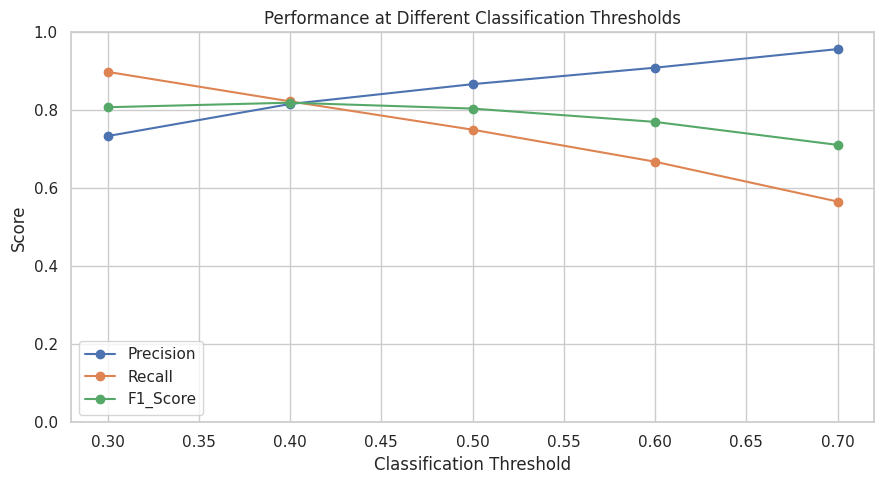

In [71]:
threshold_plot_df = threshold_results_df.set_index(
    "Threshold"
)

threshold_plot_df.plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.title("Performance at Different Classification Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Step 31: Check model calibration

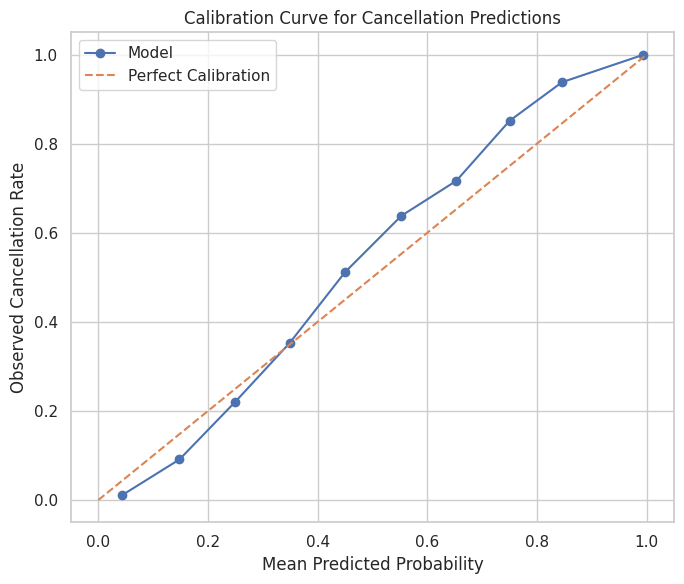

In [72]:
probabilities = best_model.predict_proba(X_test)[:, 1]

fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test,
    probabilities,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label="Model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.title("Calibration Curve for Cancellation Predictions")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Cancellation Rate")
plt.legend()
plt.tight_layout()
plt.show()

# Step 32: Save all important results

In [73]:
# Save model comparison
results_df.to_csv(
    "model_evaluation_results.csv",
    index=False
)

# Save threshold analysis
threshold_results_df.to_csv(
    "threshold_analysis_results.csv",
    index=False
)

# Save risk predictions
risk_output.to_csv(
    "booking_cancellation_risk_predictions.csv",
    index=False
)

# Save risk-group performance
risk_performance.to_csv(
    "booking_risk_group_analysis.csv",
    index=False
)

# Save permutation importance
permutation_df.to_csv(
    "permutation_feature_importance.csv",
    index=False
)

# Save Random Forest feature importance
feature_importance_df.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)

print("All analysis results have been saved.")

All analysis results have been saved.


# Step 33: Save the trained model

In [74]:
joblib.dump(
    best_model,
    "hotel_cancellation_prediction_model.pkl"
)

print("Best model saved successfully.")

Best model saved successfully.


# Step 34: Save the cleaned dataset

In [75]:
df.to_csv(
    "hotel_bookings_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


# Step 35: Create a final project summary

In [76]:
best_result = results_df.loc[
    results_df["ROC_AUC"].idxmax()
]

project_summary = pd.DataFrame({
    "Project": [
        "Hotel Booking Cancellation Prediction"
    ],
    "Dataset_Rows": [
        len(df)
    ],
    "Dataset_Columns": [
        df.shape[1]
    ],
    "Training_Rows": [
        len(X_train)
    ],
    "Testing_Rows": [
        len(X_test)
    ],
    "Selected_Model": [
        best_result["Model"]
    ],
    "Accuracy": [
        best_result["Accuracy"]
    ],
    "Precision": [
        best_result["Precision"]
    ],
    "Recall": [
        best_result["Recall"]
    ],
    "F1_Score": [
        best_result["F1_Score"]
    ],
    "ROC_AUC": [
        best_result["ROC_AUC"]
    ]
})

display(
    project_summary.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_Score": "{:.4f}",
        "ROC_AUC": "{:.4f}"
    })
)

,Project,Dataset_Rows,Dataset_Columns,Training_Rows,Testing_Rows,Selected_Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Hotel Booking Cancellation Prediction,119210,34,95368,23842,Random Forest,0.8647,0.8689,0.7477,0.8038,0.9412


In [77]:
project_summary.to_csv(
    "final_project_summary.csv",
    index=False
)